## Parte A: Regresión Lineal y No Lineal
### Caso 1: Coeficiente de fricción en función de la velocidad

En un banco de pruebas de transmisión, se midió el coeficiente de fricción μ en función de la
velocidad angular ω (rad/s).

--- REGRESIÓN LINEAL ---
Ecuación: mu = 0.3970 + -0.000230*omega | R² = 0.9653

--- POLINOMIO DE SEGUNDO ORDEN ---
ECM = 0.00000229

--- REGRESIÓN EXPONENCIAL ---
Ecuación: mu = 0.4020 * exp(-0.000695*omega) | R² = 0.9779


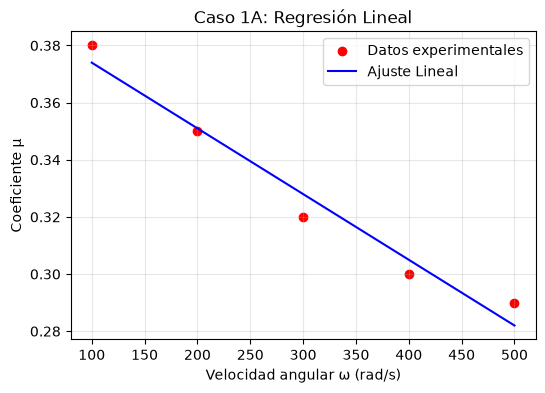

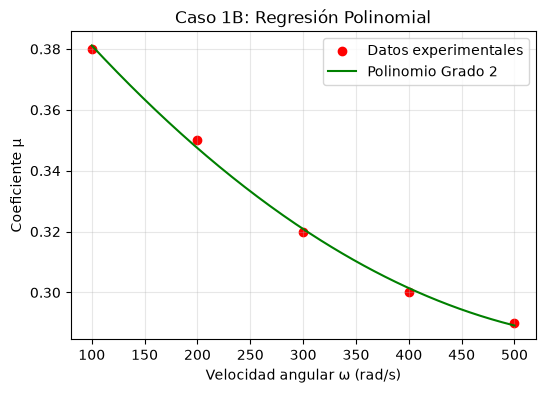

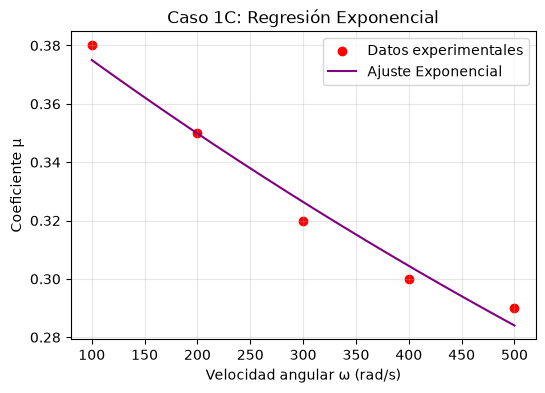

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Datos experimentales
omega = np.array([100, 200, 300, 400, 500])
mu = np.array([0.38, 0.35, 0.32, 0.30, 0.29])

# Función auxiliar para calcular el coeficiente de determinación R²
def calcular_r2(y_real, y_est):
    ss_res = np.sum((y_real - y_est) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1 - (ss_res / ss_tot)

 # 1. Ajuste lineal: mu = a + b*omega (polyfit devuelve [b, a] para grado 1)
b, a = np.polyfit(omega, mu, 1)
mu_lineal = np.polyval([b, a], omega)
r2_lin = calcular_r2(mu, mu_lineal)
print(f"--- REGRESIÓN LINEAL ---")
print(f"Ecuación: mu = {a:.4f} + {b:.6f}*omega | R² = {r2_lin:.4f}\n")

 # 2. Ajuste polinomial de segundo orden
coef_poli = np.polyfit(omega, mu, 2)
mu_poli = np.polyval(coef_poli, omega)
ecm = np.mean((mu - mu_poli) ** 2)
print(f"--- POLINOMIO DE SEGUNDO ORDEN ---")
print(f"ECM = {ecm:.8f}\n")

 # 3. Ajuste exponencial: mu = alpha * exp(beta * omega)
beta, ln_alpha = np.polyfit(omega, np.log(mu), 1)
alpha = np.exp(ln_alpha)
mu_exp = alpha * np.exp(beta * omega)
r2_exp = calcular_r2(mu, mu_exp)
print(f"--- REGRESIÓN EXPONENCIAL ---")
print(f"Ecuación: mu = {alpha:.4f} * exp({beta:.6f}*omega) | R² = {r2_exp:.4f}")


x_smooth = np.linspace(omega.min(), omega.max(), 200)

# Gráfica 1: Lineal
plt.figure(figsize=(6, 4))
plt.scatter(omega, mu, color="red", label="Datos experimentales")
plt.plot(x_smooth, np.polyval([b, a], x_smooth), color="blue", label="Ajuste Lineal")
plt.title("Caso 1A: Regresión Lineal")
plt.xlabel("Velocidad angular ω (rad/s)")
plt.ylabel("Coeficiente μ")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Gráfica 2: Polinomial
plt.figure(figsize=(6, 4))
plt.scatter(omega, mu, color="red", label="Datos experimentales")
plt.plot(x_smooth, np.polyval(coef_poli, x_smooth), color="green", label="Polinomio Grado 2")
plt.title("Caso 1B: Regresión Polinomial")
plt.xlabel("Velocidad angular ω (rad/s)")
plt.ylabel("Coeficiente μ")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Gráfica 3: Exponencial
plt.figure(figsize=(6, 4))
plt.scatter(omega, mu, color="red", label="Datos experimentales")
plt.plot(x_smooth, alpha * np.exp(beta * x_smooth), color="purple", label="Ajuste Exponencial")
plt.title("Caso 1C: Regresión Exponencial")
plt.xlabel("Velocidad angular ω (rad/s)")
plt.ylabel("Coeficiente μ")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Usando GitHub Copilot logre estructurar el código de manera rápida utilizando funciones básicas (dadas por el PDF) de NumPy como polyfit para calcular los ajustes lineal, polinomial y exponencial mediante la linealización de los datos. Copilot me ayudó a generar las fórmulas matemáticas y el cálculo del coeficiente de determinación R^2 y el Error Cuadrático Medio sin enredarme con códigos muy largos. Al final, decidí graficar cada modelo por separado con Matplotlib para visualizar de forma más limpia y ordenada cómo se comporta cada curva en comparación con los puntos experimentales medidos en el banco de pruebas.

## Parte B: Interpolación Numérica
### Caso 3: Propiedades térmicas de un metal
Las pérdidas de carga ℎ𝑓(m) se midieron a diferentes caudales 𝑄(L/s) para un tubo de acero de 25
mm de diámetro.

k = 0.2086
n = 2.1198


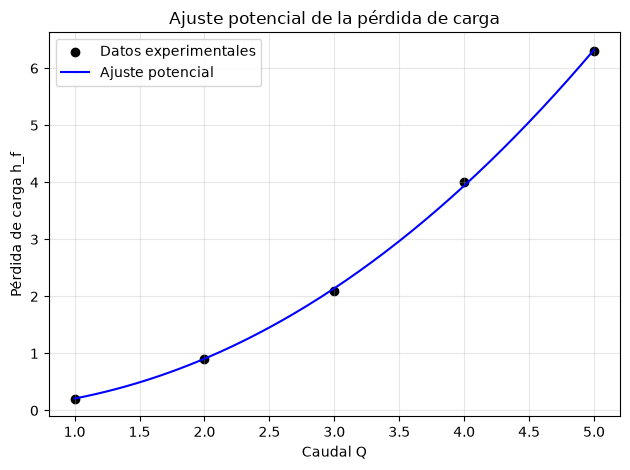

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Datos experimentales
Q = np.array([1, 2, 3, 4, 5])
h_f = np.array([0.2, 0.9, 2.1, 4.0, 6.3])

# Modelo potencial
def modelo(Q, k, n):
    return k * (Q**n)

# Ajuste de k y n
parametros, _ = curve_fit(modelo, Q, h_f, p0=(0.2, 2))
k, n = parametros
print(f"k = {k:.4f}")
print(f"n = {n:.4f}")

# Curva suave para la gráfica
Q_suave = np.linspace(Q.min(), Q.max(), 200)
h_f_ajustado = modelo(Q_suave, k, n)

plt.scatter(Q, h_f, color="black", label="Datos experimentales")
plt.plot(Q_suave, h_f_ajustado, color="blue", label="Ajuste potencial")
plt.title("Ajuste potencial de la pérdida de carga")
plt.xlabel("Caudal Q")
plt.ylabel("Pérdida de carga h_f")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Para resolver este caso no lineal, Copilot sugirió utilizar la función curve_fit de la librería scipy.optimize, la cual es ideal para ajustar modelos de tipo potencia como el que exige el problema h_f = kQ^n. Esto permitió obtener de forma directa los valores óptimos de las constantes k y n que relacionan el caudal con las pérdidas de carga. La gráfica muestra una curva suave que encaja muy bien con los puntos experimentales.